In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("smartcart_customers.csv")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [3]:
df.shape

(2240, 22)

In [4]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Data preprocessing

1. Handle Missing Values

In [5]:
df["Income"] = df["Income"].fillna(df["Income"].median())

In [6]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

# Feature Engeenering

In [7]:
# Age
df["Age"] = 2026-df["Year_Birth"]

In [8]:
#customer joining date & make new feature customer tenure days
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"],dayfirst=True)

reference_date = df["Dt_Customer"].max()
df["Customer_Tenure_days"]  = (reference_date - df["Dt_Customer"]).dt.days

In [9]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [10]:

# Spending

df["Total_spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [11]:
# children

df["total_children"] = df["Kidhome"] + df["Teenhome"]

In [12]:
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days,Total_spending,total_children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1445,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,25,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,665,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,43,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,376,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,...,9,3,4,5,0,0,59,381,1299,1
2236,4001,1946,PhD,Together,64014.0,2,1,2014-06-10,56,406,...,8,2,5,7,0,0,80,19,444,3
2237,7270,1981,Graduation,Divorced,56981.0,0,0,2014-01-25,91,908,...,2,3,13,6,0,0,45,155,1209,0
2238,8235,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,...,6,5,10,3,0,0,70,156,763,1


In [13]:
# education
df["Education"].value_counts()

df["Education"] = df["Education"].replace({
    "Basic":"under_graduate","2n Cycle":"under_graduate",
    "Graduation":"graduate",
    "PhD":"post_graduate","Master":"post_graduate"
})

In [14]:
 df["Education"].value_counts()

Education
graduate          1127
post_graduate      856
under_graduate     257
Name: count, dtype: int64

In [15]:
# Marital_status

df["Living_with"] = df["Marital_Status"].replace({
    "YOLO":"Alone","Absurd":"Alone","Widow":"Alone",
    "Divorced":"Alone","Single":"Alone","Married":"partner",
    "Together":"partner"
})

In [16]:
df["Living_with"].value_counts()

Living_with
partner    1444
Alone       796
Name: count, dtype: int64

# drop columns

In [17]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days,Total_spending,total_children,Living_with
0,5524,1957,graduate,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1445,0,Alone
1,2174,1954,graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,25,2,Alone
2,4141,1965,graduate,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,665,0,partner
3,6182,1984,graduate,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,43,1,partner
4,5324,1981,post_graduate,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,376,1,partner


In [18]:
cols = ["ID","Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer"]
spending_cols = ["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]

columns_to_drop = cols + spending_cols

In [19]:
df_cleaned = df.drop(columns = columns_to_drop)

In [20]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days,Total_spending,total_children,Living_with
0,graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1445,0,Alone
1,graduate,46344.0,38,2,1,1,2,5,0,0,72,113,25,2,Alone
2,graduate,71613.0,26,1,8,2,10,4,0,0,61,312,665,0,partner
3,graduate,26646.0,26,2,2,0,4,6,0,0,42,139,43,1,partner
4,post_graduate,58293.0,94,5,5,3,6,5,0,0,45,161,376,1,partner


# Outliers

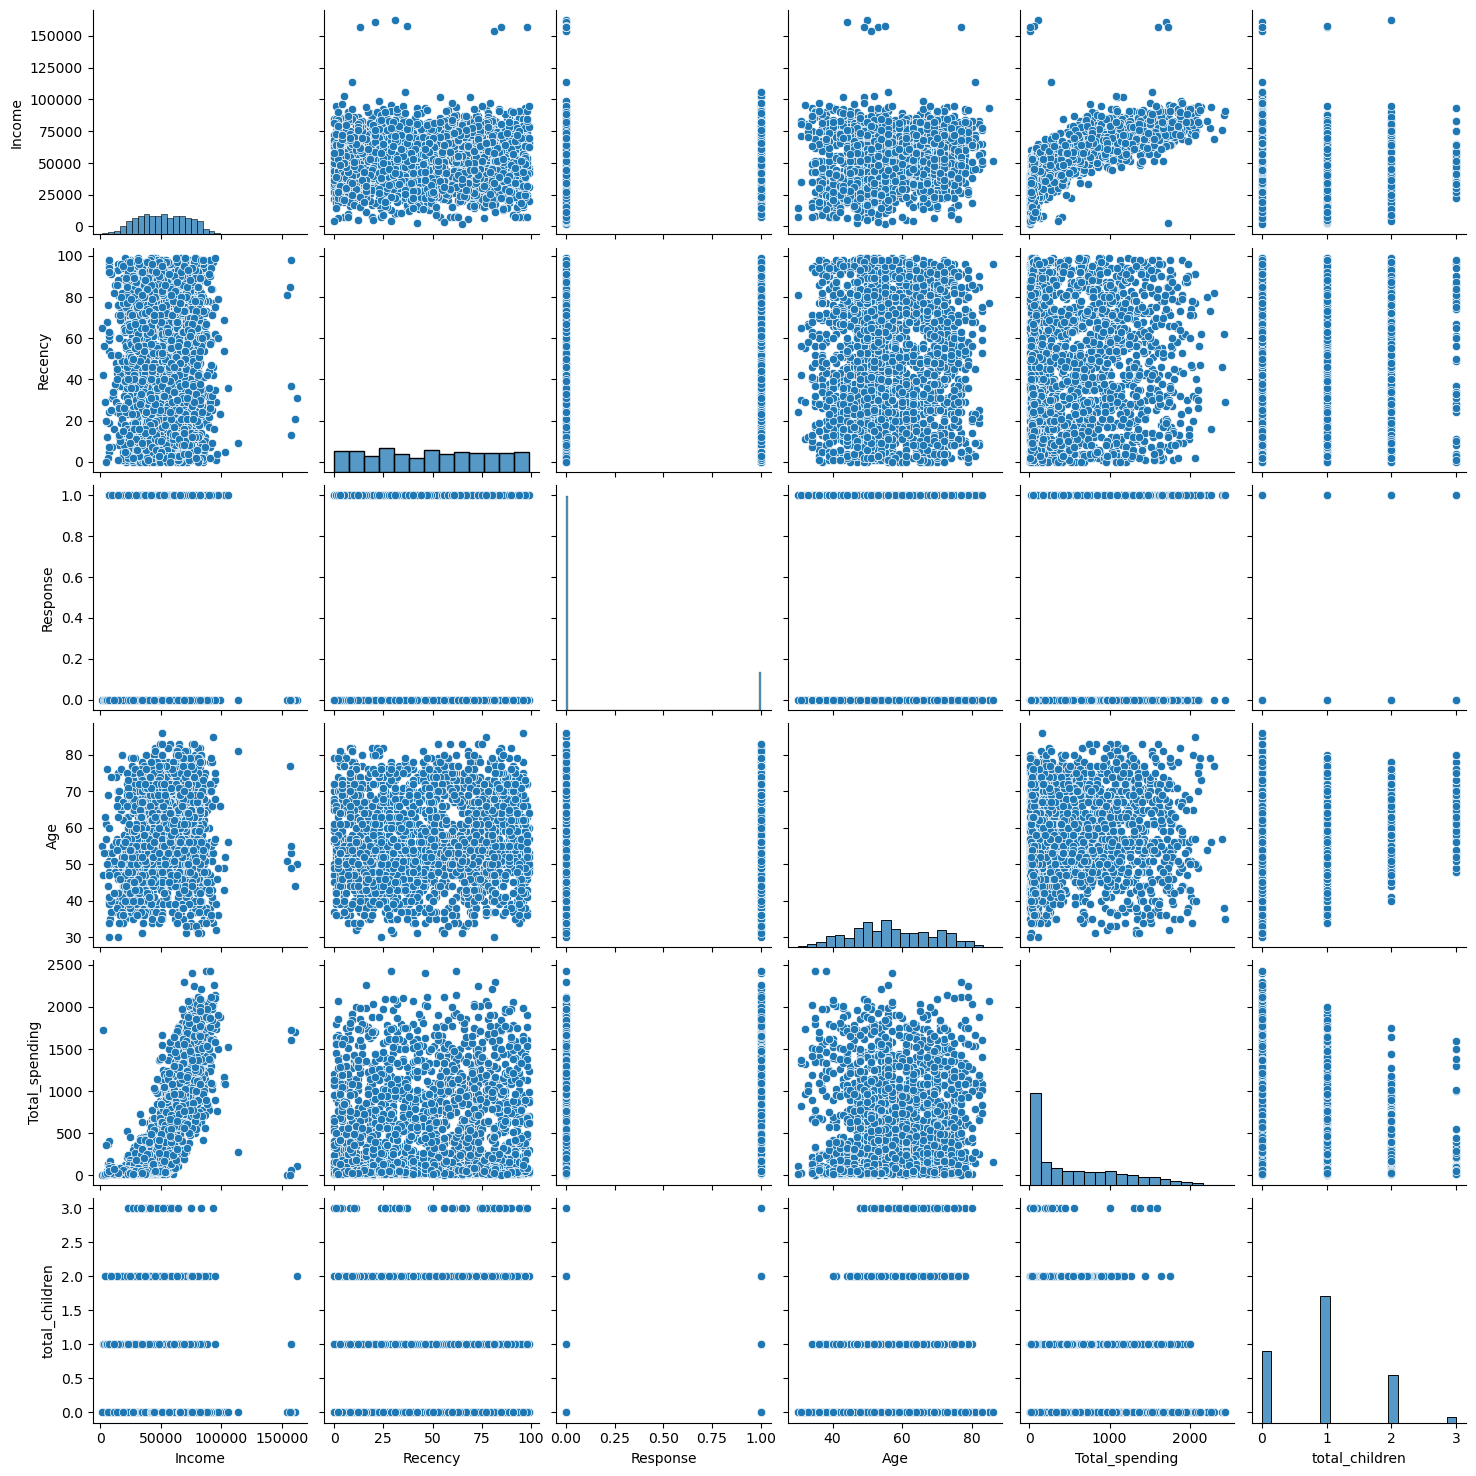

In [76]:
cols = ["Income","Recency","Response","Age","Total_spending","total_children"]

# relative plots of some features - pair plots
sns.pairplot(df_cleaned[cols])

In [22]:
# remove the outliers

print("data size with outliers:",len(df_cleaned))

df_cleaned = df_cleaned[ (df_cleaned["Age"] < 90) ]
df_cleaned = df_cleaned[(df_cleaned["Income"]<600_000)]

print("data size without outliers:",len(df_cleaned))

data size with outliers: 2240
data size without outliers: 2236


# Heatmap

In [23]:
corr = df_cleaned.corr(numeric_only = True)

In [24]:
corr

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days,Total_spending,total_children
Income,1.000000,0.007829,-0.107169,0.450584,0.693781,0.628075,-0.646382,-0.027871,0.161121,0.198835,-0.023677,0.786130,-0.340550
Recency,0.007829,1.000000,-0.000638,-0.010776,0.025226,0.000771,-0.021850,0.005361,-0.198781,0.019396,0.024238,0.021947,0.017826
NumDealsPurchases,-0.107169,-0.000638,1.000000,0.233971,-0.008510,0.068418,0.347216,0.003636,0.002017,0.068286,0.218009,-0.055267,0.439682
NumWebPurchases,0.450584,-0.010776,0.233971,1.000000,0.378049,0.502227,-0.056204,-0.013250,0.148390,0.153873,0.191211,0.522434,-0.146429
NumCatalogPurchases,0.693781,0.025226,-0.008510,0.378049,1.000000,0.518788,-0.520376,-0.018304,0.220813,0.125285,0.095836,0.772956,-0.439631
NumStorePurchases,0.628075,0.000771,0.068418,0.502227,0.518788,1.000000,-0.429857,-0.011563,0.038702,0.139237,0.109727,0.671111,-0.321729
NumWebVisitsMonth,-0.646382,-0.021850,0.347216,-0.056204,-0.520376,-0.429857,1.000000,0.020796,-0.004397,-0.117498,0.272105,-0.486566,0.417908
Complain,-0.027871,0.005361,0.003636,-0.013250,-0.018304,-0.011563,0.020796,1.000000,0.000167,0.004450,0.035685,-0.033967,0.031480
Response,0.161121,-0.198781,0.002017,0.148390,0.220813,0.038702,-0.004397,0.000167,1.000000,-0.018557,0.194232,0.270594,-0.169451
Age,0.198835,0.019396,0.068286,0.153873,0.125285,0.139237,-0.117498,0.004450,-0.018557,1.000000,-0.016451,0.116253,0.095512


<Axes: >

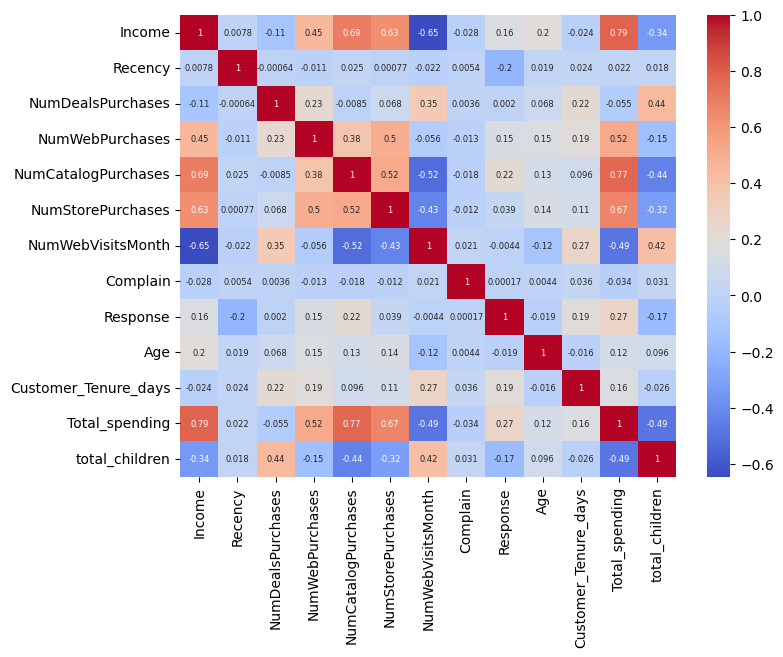

In [25]:
plt.figure(figsize = (8,6))
sns.heatmap(
    corr,
    annot = True,
    annot_kws = {"size":6},
    cmap = "coolwarm"
)
    

In [75]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days,Total_spending,total_children,Living_with,labels,clusters
0,graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1445,0,Alone,3,3
1,graduate,46344.0,38,2,1,1,2,5,0,0,72,113,25,2,Alone,2,2
2,graduate,71613.0,26,1,8,2,10,4,0,0,61,312,665,0,partner,0,0
3,graduate,26646.0,26,2,2,0,4,6,0,0,42,139,43,1,partner,1,1
4,post_graduate,58293.0,94,5,5,3,6,5,0,0,45,161,376,1,partner,1,1


Encoding

In [27]:
 from sklearn.preprocessing import OneHotEncoder


In [28]:
ohe = OneHotEncoder()

cat_cols  = ["Education","Living_with"]

enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [29]:
enc_df = pd.DataFrame(enc_cols.toarray(),columns = ohe.get_feature_names_out(cat_cols),index = df_cleaned.index)

In [30]:
df_encoded = pd.concat([df_cleaned.drop(columns = cat_cols) , enc_df],axis= 1)

In [31]:
df_encoded.shape

(2236, 18)

In [32]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days,Total_spending,total_children,Education_graduate,Education_post_graduate,Education_under_graduate,Living_with_Alone,Living_with_partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1445,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,25,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,665,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,43,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,376,1,0.0,1.0,0.0,0.0,1.0


In [33]:
x = df_encoded

# scaling

In [34]:
from sklearn.preprocessing import StandardScaler

std = StandardScaler()
x_scaled = std.fit_transform(x)

In [35]:
x_scaled

array([[ 0.28894655,  0.30685572,  0.34873831, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [-0.262003  , -0.38397129, -0.16869955, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [ 0.91842301, -0.7984675 , -0.68613742, ..., -0.35877969,
        -0.74204052,  0.74204052],
       ...,
       [ 0.234898  ,  1.44672029, -0.68613742, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [ 0.80780332, -1.42021181, -0.16869955, ..., -0.35877969,
        -0.74204052,  0.74204052],
       [ 0.04280841, -0.31488859,  0.34873831, ..., -0.35877969,
        -0.74204052,  0.74204052]], shape=(2236, 18))

# visualize

In [36]:
x_scaled.shape

(2236, 18)

In [37]:
# 2D
from sklearn.decomposition import PCA


In [38]:
pca = PCA(
    n_components = 3
)
x_pca = pca.fit_transform(x_scaled)


In [39]:
pca.explained_variance_ratio_

array([0.2311121 , 0.11385568, 0.10411264])

Text(0.5, 0.92, '3d projection')

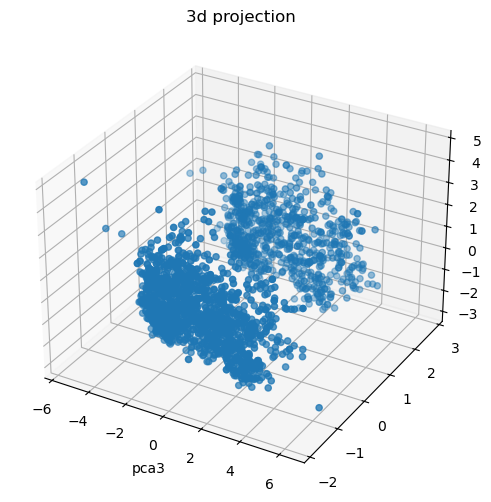

In [40]:
#plot - here it new thing we learn is 3d projection using add_subplot
fig = plt.figure(figsize = (8,6))
ax = fig.add_subplot(111,projection="3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2])

ax.set_xlabel("pca1")
ax.set_xlabel("pca2")
ax.set_xlabel("pca3")
ax.set_title("3d projection")

In [41]:
pca.explained_variance_ratio_

array([0.2311121 , 0.11385568, 0.10411264])

# analyze k value

In [42]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters = k,random_state = 42)
    kmeans.fit_predict(x_pca)
    wcss.append(kmeans.inertia_)

In [43]:
knee = KneeLocator(range(1,11),wcss,curve="convex",direction = "decreasing")
optimal_k = knee.elbow

In [44]:
print("best k=",optimal_k)

best k= 4


Text(0, 0.5, 'WCSS')

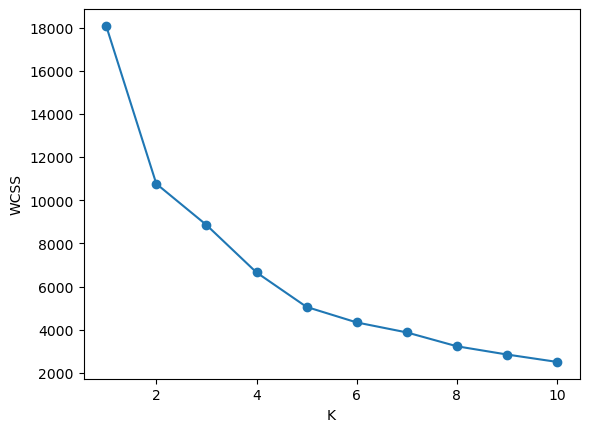

In [45]:
#plot (second method for k value)
plt.plot(range(1,11),wcss,marker = 'o')
plt.xlabel("K")
plt.ylabel("WCSS")


# Clustering


In [46]:
# kmeans

kmeans = KMeans(n_clusters = 4,random_state = 42)
labels_kmeans = kmeans.fit_predict(x_pca)

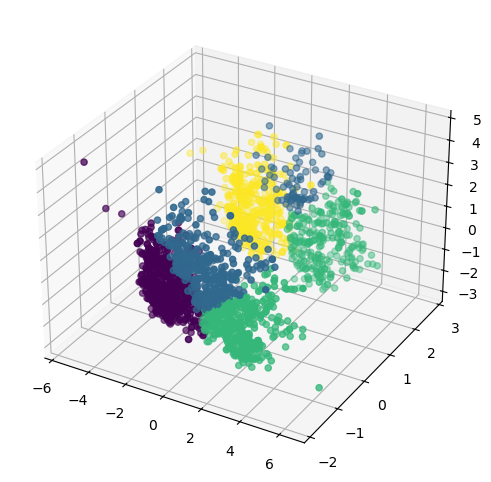

In [47]:
# 3d plotting

fig = plt.figure(figsize = (8,6))
ax = fig.add_subplot(111,projection = "3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2],c = labels_kmeans)

In [48]:
# Agglomerative clustering

from sklearn.cluster import AgglomerativeClustering


In [50]:
agg_clf = AgglomerativeClustering(n_clusters = 4,linkage = "ward")
labels_agg_clf = agg_clf.fit_predict(x_pca)

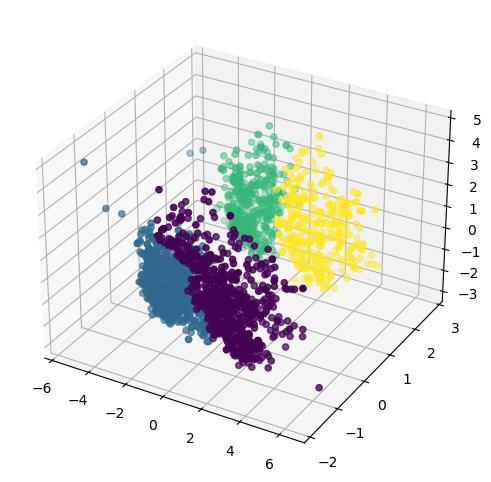

In [51]:
fig = plt.figure(figsize = (8,6))
ax = fig.add_subplot(111,projection = "3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2],c = labels_agg_clf)

In [61]:
#DBSCAN
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps = 0.5,
    min_samples = 12
)

In [62]:
labels = dbscan.fit_predict(x_pca)


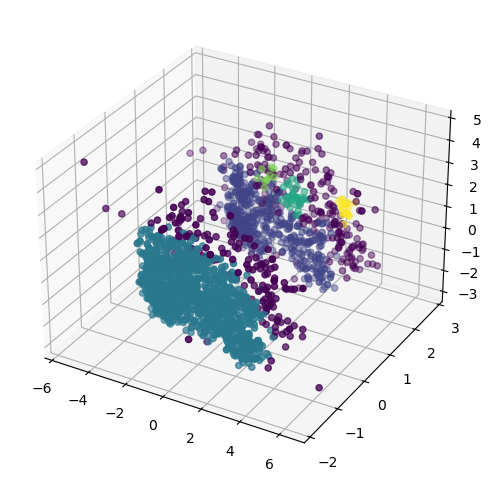

In [63]:
fig = plt.figure(figsize = (8,6))
ax = fig.add_subplot(111,projection = "3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2],c = labels)

# characterisation of clusters



In [68]:
df_cleaned.drop("labels",axis = 1)
df_cleaned["clusters"] = labels_agg_clf

In [69]:
df_cleaned .head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days,Total_spending,total_children,Living_with,labels,clusters
0,graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1445,0,Alone,3,3
1,graduate,46344.0,38,2,1,1,2,5,0,0,72,113,25,2,Alone,2,2
2,graduate,71613.0,26,1,8,2,10,4,0,0,61,312,665,0,partner,0,0
3,graduate,26646.0,26,2,2,0,4,6,0,0,42,139,43,1,partner,1,1
4,post_graduate,58293.0,94,5,5,3,6,5,0,0,45,161,376,1,partner,1,1


<Axes: xlabel='clusters', ylabel='count'>

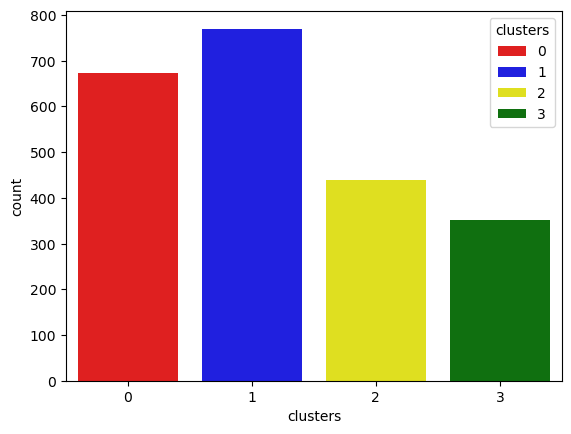

In [70]:
# for calcualting the number of customers in each colour we creat ecolour palate
pal = ["red","blue","yellow","green"]
sns.countplot(x = df_cleaned["clusters"],palette = pal,hue = df_cleaned["clusters"])

<Axes: xlabel='Total_spending', ylabel='Income'>

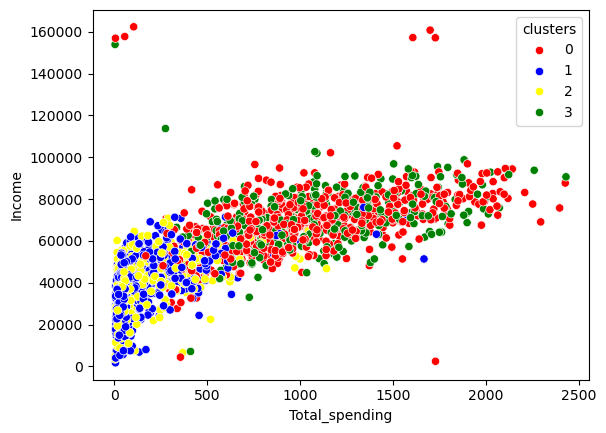

In [74]:
# income and spending patterns

sns.scatterplot(x = df_cleaned["Total_spending"],y=df_cleaned["Income"],hue = df_cleaned["clusters"],palette = pal)